# MINT final test (E5, OPV2V): results notebook

Reads **only** the two analysis summaries (`e5_v3.json` from `v3_analyze`, `e5_test.json` from the frozen v2 `e5_analyze`) and shows every pre-registered statistic, figure and check. Nothing is recomputed; the numbers are those in the files. The status banner says whether these are final-test results or development numbers. An incomplete final test stops the notebook (pre-registered rule: no AP or criteria on partial results).

To point it at the final test, change the paths in the next cell to `runs/20261024-E5v3/e5_v3.json` and `runs/20261024-E5v3/e5_test.json`.

In [1]:
# Inputs (relative to the repository root)
V3 = 'runs/20261024-PGD/pgd_stealth_H_results.json'
V2 = 'runs/20261024-E5/H/e5a_H.json'
PREREG = 'runs/20261024-E5/preregistration_v3_2.json'


In [2]:
import os, sys, time, platform
from IPython.display import Markdown, display
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'src'))
import io
import matplotlib.pyplot as plt
from IPython.display import Image
from mint.report import style, tables as T
from mint.report.data import Inputs, DEFS, DEF_NAME
from mint.report.figures import FIGURES
T0 = time.time()
inp = Inputs(os.path.join(ROOT, V3), os.path.join(ROOT, V2) if V2 else None,
             os.path.join(ROOT, PREREG) if PREREG else None, root=ROOT)
if inp.status == 'INCOMPLETE':
    raise SystemExit('STOP: the final-test analysis is flagged incomplete; no AP or criteria on partial results.')
display(Markdown(f'> **Status: {inp.status_text}**  \n> {inp.label}'))

> **Status: DEVELOPMENT / DRY RUN - not results**  
> DEVELOPMENT, block H (exposed, D-53); stealth PGD = attack design on exposed H, POST HOC (D-68 as amended); 4 scenarios, n = 2; not a test

## Provenance

In [3]:
p = inp.provenance()
rows = [[k, f"`{v['path']}`", f"`{v['sha256'][:16]}...`"] for k, v in p['inputs'].items()]
rows += [['git HEAD', f"`{p['git_head']}`", ''], ['frozen code commit', f"`{p['frozen_code_commit']}`", ''],
         ['scenarios / frames', f'{inp.n_scenarios()} / {inp.n_frames()}', '']]
display(Markdown(T.md(['item', 'value', 'sha256'], rows)))

| item | value | sha256 |
|---|---|---|
| e5_v3.json | `runs/20261024-PGD/pgd_stealth_H_results.json` | `38b8442555739930...` |
| e5_test.json | `runs/20261024-E5/H/e5a_H.json` | `ce87df11255a20a0...` |
| preregistration | `runs/20261024-E5/preregistration_v3_2.json` | `8756868def368e85...` |
| git HEAD | `5642cecb3dfea2823018b125e6a19a8af431feb6` |  |
| frozen code commit | `c883753f91c75e707d5df5fce8757851fad494de` |  |
| scenarios / frames | 4 / 371 |  |

## Procedural checks

In [4]:
display(Markdown(T.checks(inp)))

| Check | Detail | Passed |
|---|---|---|
| Completeness (scenarios, frames) | not recorded (development file) | n/a |
| Frame-order v3 = frozen v2 analysis | 4 statistics, point and scenario CI | n/a |
| NumPy AP vs OpenCOOD AP | max abs. difference 2.7e-14 | yes |
| Compose checks identical (all scenarios) | 4 scenarios | yes |

## Pre-registered verdict (D-64) and key secondary

In [5]:
v = T.verdict(inp)
display(Markdown(f"**Verdict:** {v['verdict']}  \nv2 rule, global-ranking AP: {v['pass_global']}; frame-order AP: {v['pass_frame']}"))
display(Markdown(T.criteria(inp)))
display(Markdown(T.r1_minus_bray(inp)))

**Verdict:** success under both AP definitions  
v2 rule, global-ranking AP: True; frame-order AP: True

| AP definition | B-RAY ΔAP | B-RAY p (1-sided) | B-RAY Holm reject | R1 ΔAP | R1 p | R1 Holm reject | B-RAY clean loss CI (%) | clean CI high ≤ 1% | v2 rule passes |
|---|---|---|---|---|---|---|---|---|---|
| global-ranking AP (headline) | +0.56 | 0.0005 | yes | +0.85 | 0.0005 | yes | [+0.03, +0.49] | yes | yes |
| frame-order AP (OPV2V-comparable) | +2.79 | 0.0005 | yes | +2.23 | 0.0550 | no | [-0.19, +0.41] | yes | yes |

| AP definition | R1 − B-RAY (pts) | 95% CI scen. | 95% CI 10-frame | Pre-registered statement |
|---|---|---|---|---|
| global-ranking AP (headline) | +0.29 | [+0.05, +0.57] | [+0.10, +0.47] | “the counterfactual improves over the box-level filter” |
| frame-order AP (OPV2V-comparable) | -0.56 | [-1.75, +0.32] | [-0.91, -0.24] | “the counterfactual's benefit over a box-level filter is not established” |

## Headline table

In [6]:
display(Markdown(T.headline(inp)))
display(Markdown(T.clean_cost(inp)))

| Method | ΔAP@0.7 global | 95% CI scen. global | 95% CI 10-frame global | ΔAP@0.7 frame | 95% CI scen. frame | 95% CI 10-frame frame |
|---|---|---|---|---|---|---|
| B-RAY (primary) | +0.56 | [+0.24, +0.82] | [+0.38, +0.73] | +2.79 | [+0.71, +4.04] | [+2.34, +3.24] |
| R1 (key secondary) | +0.85 | [+0.55, +0.98] | [+0.65, +1.04] | +2.23 | [-0.35, +3.15] | [+1.72, +2.74] |
| R1-noREMOVE (ablation) | +0.64 | [+0.35, +0.88] | [+0.49, +0.79] | +2.44 | [+0.64, +3.50] | [+2.02, +2.89] |
| B-NORM (baseline) | -0.42 | [-0.59, -0.05] | [-0.91, -0.11] | -0.44 | [-0.62, -0.09] | [-0.97, -0.11] |
| Ego-only | -15.23 | [-18.53, -12.94] | [-17.68, -12.87] | -14.58 | [-19.64, -12.64] | [-17.37, -11.93] |

| Method | rel. loss global | 95% CI scen. (%) global | rel. loss frame | 95% CI scen. (%) frame |
|---|---|---|---|---|
| B-RAY (primary) | 0.18% | [+0.03, +0.49] | 0.09% | [-0.19, +0.41] |
| R1 (key secondary) | -0.11% | [-0.56, +0.26] | 0.31% | [-0.57, +2.03] |
| R1-noREMOVE (ablation) | 0.10% | [-0.00, +0.29] | 0.02% | [-0.14, +0.27] |
| B-NORM (baseline) | 0.34% | [+0.12, +0.53] | 0.43% | [+0.14, +0.73] |
| Ego-only | 20.49% | [+17.35, +24.43] | 24.33% | [+21.38, +29.65] |

## Figures

Each figure is drawn by the same function that writes the report figures; the table of plotted values is shown under it (`rows`).

### Figure 1. Headline: mean ΔAP@0.7 over the 4 original attacks

Each defense's mean change in AP@0.7 against no defense, over spoof/remove/shift (feature) and spoof (points). Dot = point estimate; thick line = 95% CI from the scenario bootstrap (the pre-registered primary CI); thin line = 10-frame-block bootstrap. Ego-only is far off-scale and is listed in the table only.

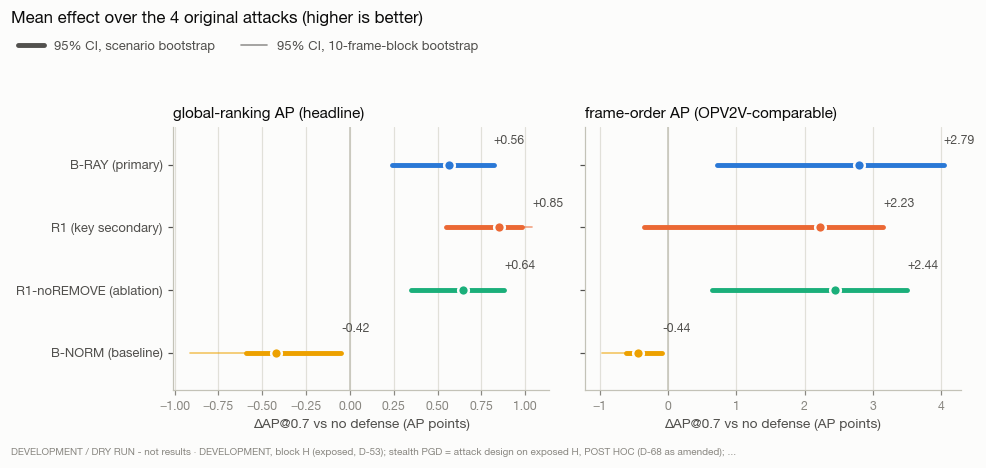

10 plotted values; first rows:
{'ap_definition': 'global', 'method': 'B-RAY', 'point': 0.00564, 'ci95_scenario_lo': 0.0024, 'ci95_scenario_hi': 0.0082, 'ci95_block10_lo': 0.0038, 'ci95_block10_hi': 0.0073}
{'ap_definition': 'global', 'method': 'R1', 'point': 0.00853, 'ci95_scenario_lo': 0.0055, 'ci95_scenario_hi': 0.0098, 'ci95_block10_lo': 0.0065, 'ci95_block10_hi': 0.0104}
{'ap_definition': 'global', 'method': 'R1_noREMOVE', 'point': 0.00643, 'ci95_scenario_lo': 0.0035, 'ci95_scenario_hi': 0.0088, 'ci95_block10_lo': 0.0049, 'ci95_block10_hi': 0.0079}
{'ap_definition': 'global', 'method': 'B-NORM', 'point': -0.00423, 'ci95_scenario_lo': -0.0059, 'ci95_scenario_hi': -0.0005, 'ci95_block10_lo': -0.0091, 'ci95_block10_hi': -0.0011}


[None, None, None, None]

In [7]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['01_headline']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 2a. ΔAP@0.7 per condition: clean and original attacks

Every non-PGD condition × defense, both AP definitions, 95% CI from the scenario bootstrap. Ego-only in the table only.

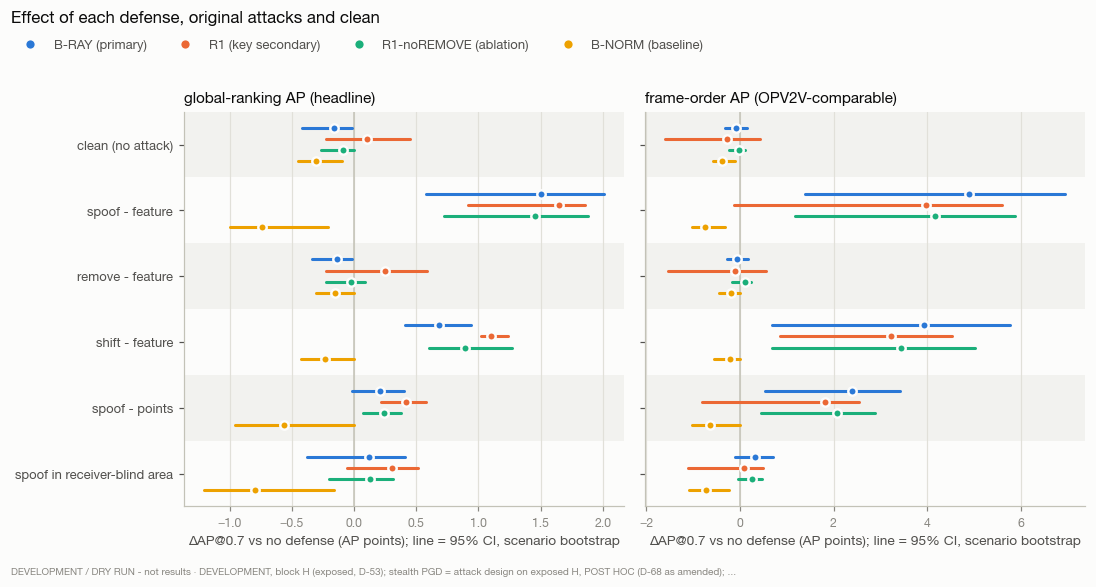

48 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'clean', 'method': 'B-RAY', 'point': -0.00161, 'ci95_scenario_lo': -0.0042, 'ci95_scenario_hi': -0.0002, 'ci95_block10_lo': -0.003, 'ci95_block10_hi': -0.0004}
{'ap_definition': 'global', 'condition': 'clean', 'method': 'R1', 'point': 0.00103, 'ci95_scenario_lo': -0.0023, 'ci95_scenario_hi': 0.0045, 'ci95_block10_lo': -0.0005, 'ci95_block10_hi': 0.0026}
{'ap_definition': 'global', 'condition': 'clean', 'method': 'R1_noREMOVE', 'point': -0.00093, 'ci95_scenario_lo': -0.0027, 'ci95_scenario_hi': 0.0, 'ci95_block10_lo': -0.0016, 'ci95_block10_hi': -0.0002}
{'ap_definition': 'global', 'condition': 'clean', 'method': 'B-NORM', 'point': -0.00308, 'ci95_scenario_lo': -0.0045, 'ci95_scenario_hi': -0.001, 'ci95_block10_lo': -0.0071, 'ci95_block10_hi': -0.0003}


[None, None, None, None]

In [8]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['02_per_family']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 2b. ΔAP@0.7 per condition: optimized (PGD) attacks

As 2a for the PGD conditions, on its own scale (PGD effects are much larger than the original attacks').

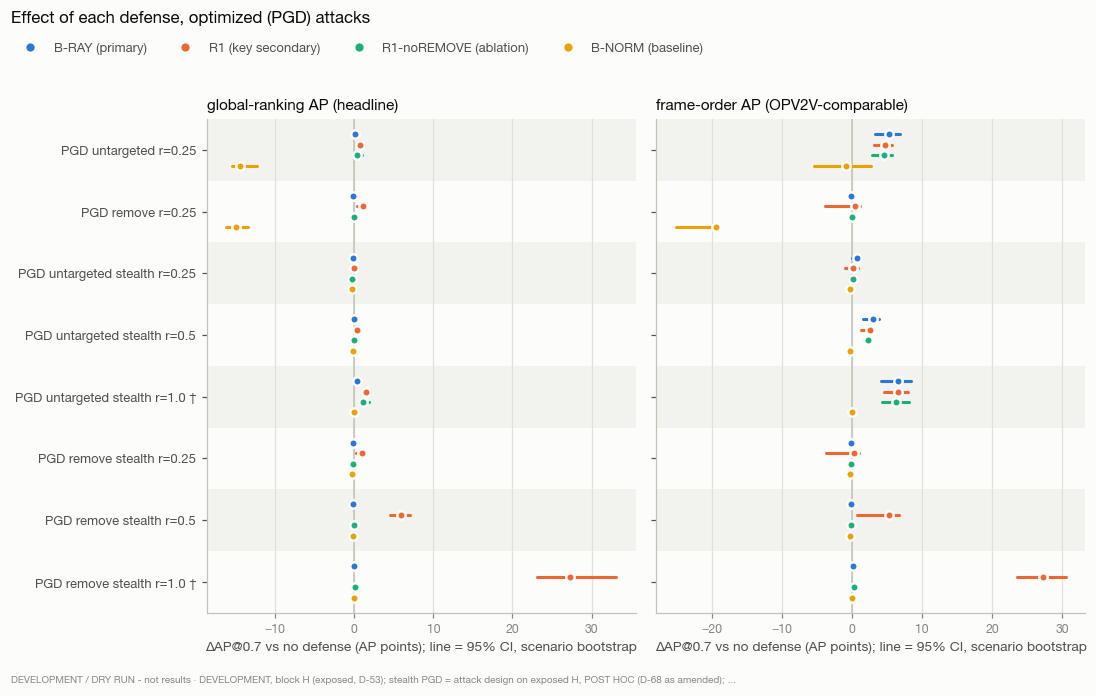

64 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-RAY', 'point': 0.00145, 'ci95_scenario_lo': 0.0003, 'ci95_scenario_hi': 0.0024, 'ci95_block10_lo': 0.0004, 'ci95_block10_hi': 0.0025}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1', 'point': 0.00681, 'ci95_scenario_lo': 0.0029, 'ci95_scenario_hi': 0.0123, 'ci95_block10_lo': 0.0025, 'ci95_block10_hi': 0.0108}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1_noREMOVE', 'point': 0.00376, 'ci95_scenario_lo': 0.0014, 'ci95_scenario_hi': 0.0099, 'ci95_block10_lo': 0.0001, 'ci95_block10_hi': 0.0069}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-NORM', 'point': -0.1438, 'ci95_scenario_lo': -0.1543, 'ci95_scenario_hi': -0.1225, 'ci95_block10_lo': -0.1716, 'ci95_block10_hi': -0.1173}


[None, None, None, None]

In [9]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['02b_per_family_pgd']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 3. Clean cost (relative AP@0.7 loss)

Relative AP@0.7 loss on clean frames. The pre-registered success rule requires B-RAY's scenario-CI high ≤ 1% under both AP definitions.

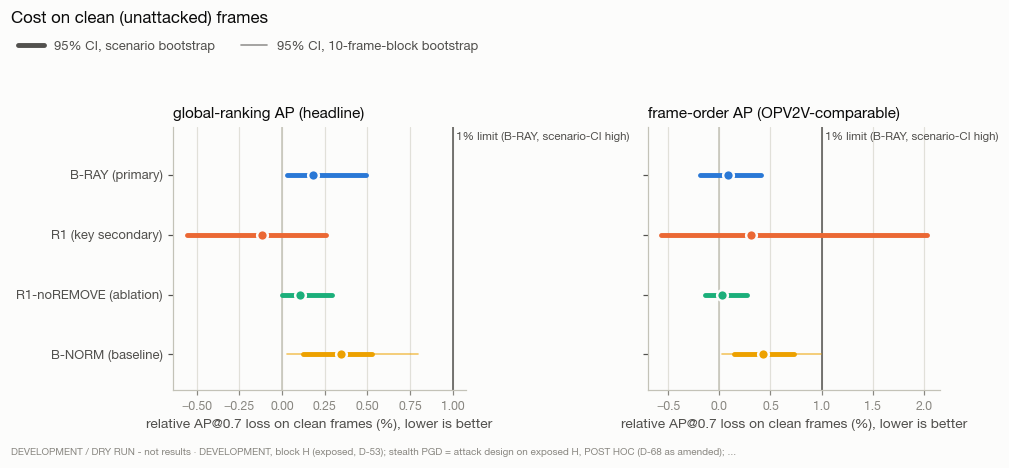

10 plotted values; first rows:
{'ap_definition': 'global', 'method': 'B-RAY', 'point': 0.0018, 'ci95_scenario_lo': 0.0003, 'ci95_scenario_hi': 0.0049, 'ci95_block10_lo': 0.0005, 'ci95_block10_hi': 0.0034}
{'ap_definition': 'global', 'method': 'R1', 'point': -0.00115, 'ci95_scenario_lo': -0.0056, 'ci95_scenario_hi': 0.0026, 'ci95_block10_lo': -0.0029, 'ci95_block10_hi': 0.0005}
{'ap_definition': 'global', 'method': 'R1_noREMOVE', 'point': 0.00104, 'ci95_scenario_lo': -0.0, 'ci95_scenario_hi': 0.0029, 'ci95_block10_lo': 0.0003, 'ci95_block10_hi': 0.0018}
{'ap_definition': 'global', 'method': 'B-NORM', 'point': 0.00345, 'ci95_scenario_lo': 0.0012, 'ci95_scenario_hi': 0.0053, 'ci95_block10_lo': 0.0003, 'ci95_block10_hi': 0.008}


[None, None, None, None]

In [10]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['03_clean_cost']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 4a. Key secondary: R1 − B-RAY

Paired difference R1 − B-RAY in ΔAP@0.7, the pre-registered means and each non-PGD condition. Each panel quotes the statement the frozen analysis emitted.

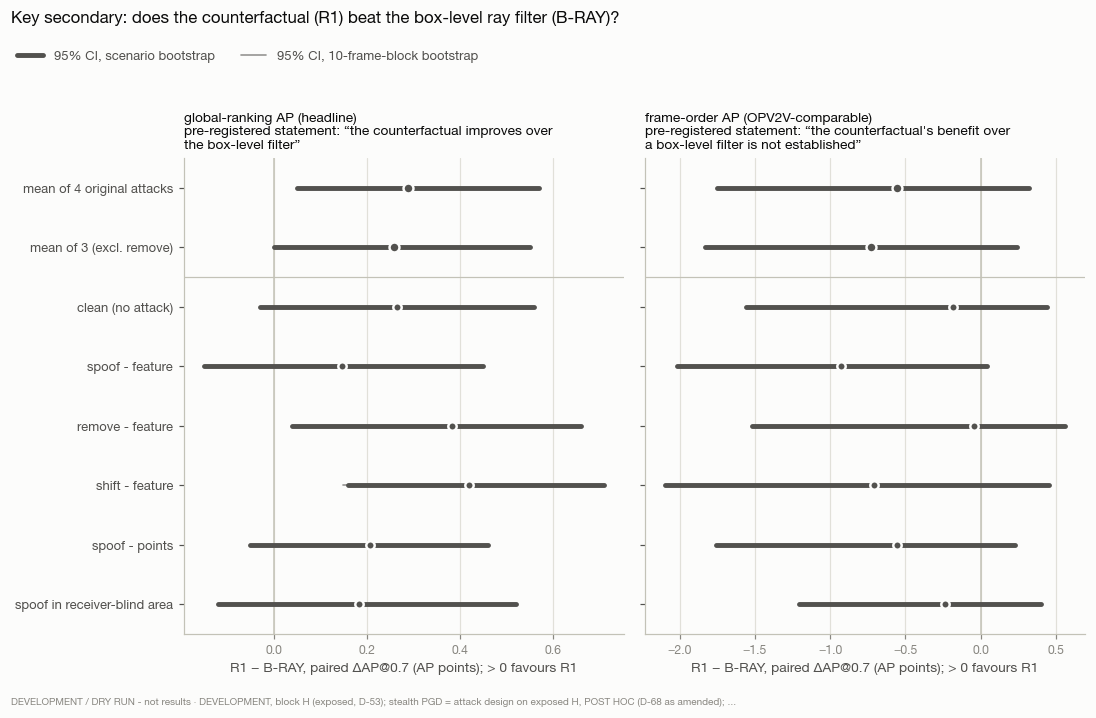

16 plotted values; first rows:
{'ap_definition': 'global', 'statistic': 'paired_mean_orig|R1-B-RAY', 'point': 0.00289, 'ci95_scenario_lo': 0.0005, 'ci95_scenario_hi': 0.0057, 'ci95_block10_lo': 0.001, 'ci95_block10_hi': 0.0047}
{'ap_definition': 'global', 'statistic': 'paired_mean_3|R1-B-RAY', 'point': 0.00258, 'ci95_scenario_lo': 0.0, 'ci95_scenario_hi': 0.0055, 'ci95_block10_lo': 0.0006, 'ci95_block10_hi': 0.0046}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|clean', 'point': 0.00264, 'ci95_scenario_lo': -0.0003, 'ci95_scenario_hi': 0.0056, 'ci95_block10_lo': 0.0008, 'ci95_block10_hi': 0.0045}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|spoof_feat', 'point': 0.00147, 'ci95_scenario_lo': -0.0015, 'ci95_scenario_hi': 0.0045, 'ci95_block10_lo': -0.0004, 'ci95_block10_hi': 0.0033}


[None, None, None, None]

In [11]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['04_r1_minus_bray']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 4b. R1 − B-RAY under PGD attacks

Paired difference per PGD condition (descriptive; not part of the key secondary).

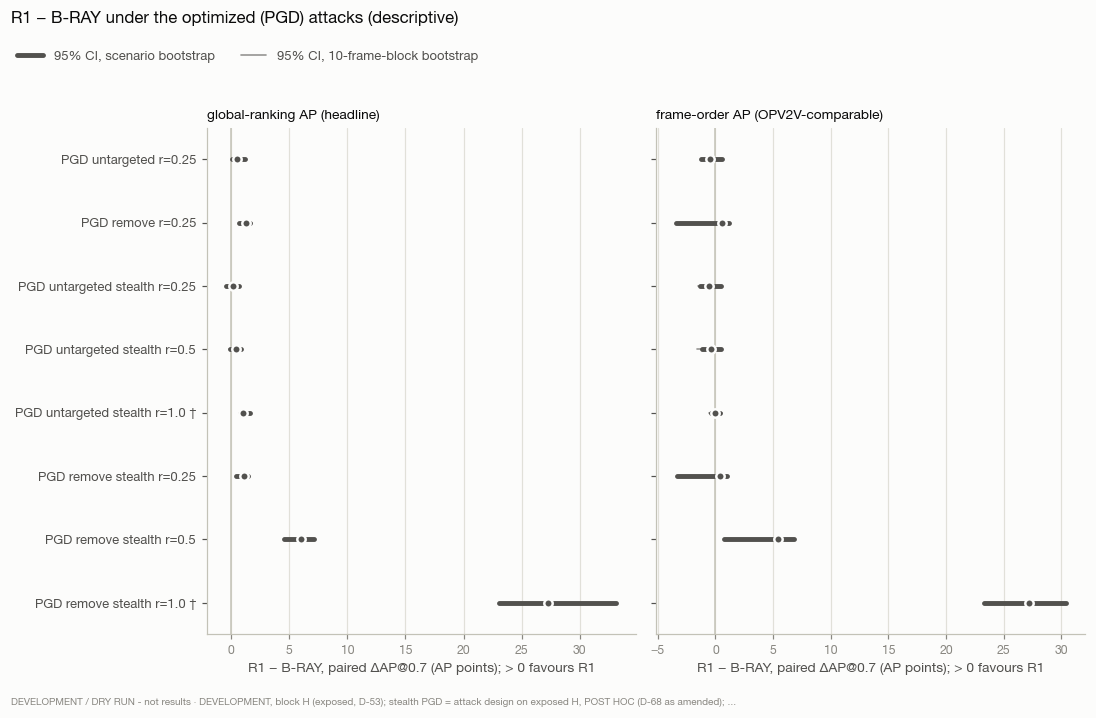

16 plotted values; first rows:
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_untargeted@r0.25', 'point': 0.00536, 'ci95_scenario_lo': 0.0006, 'ci95_scenario_hi': 0.012, 'ci95_block10_lo': 0.0009, 'ci95_block10_hi': 0.0095}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_remove@r0.25', 'point': 0.01253, 'ci95_scenario_lo': 0.0065, 'ci95_scenario_hi': 0.0159, 'ci95_block10_lo': 0.0075, 'ci95_block10_hi': 0.0177}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_untargeted_stealth@r0.25', 'point': 0.00149, 'ci95_scenario_lo': -0.0041, 'ci95_scenario_hi': 0.0066, 'ci95_block10_lo': -0.0031, 'ci95_block10_hi': 0.0052}
{'ap_definition': 'global', 'statistic': 'paired|R1-B-RAY|pgd_untargeted_stealth@r0.5', 'point': 0.00426, 'ci95_scenario_lo': -0.0005, 'ci95_scenario_hi': 0.0089, 'ci95_block10_lo': -0.0014, 'ci95_block10_hi': 0.0088}


[None, None, None, None]

In [12]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['04b_r1_minus_bray_pgd']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 5. PGD attacks: recovery

Recovery = ΔAP@0.7 / attack loss per optimized-attack condition. n/a when the attack loss is < 0.005.

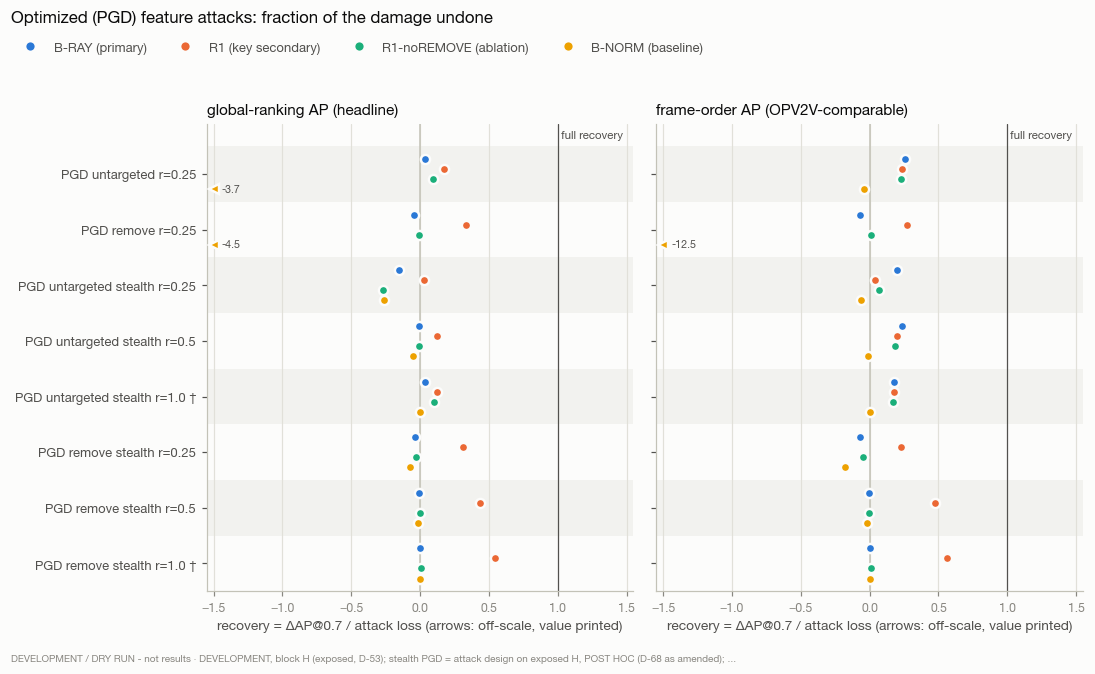

64 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-RAY', 'recovery': 0.03723, 'attack_loss': 0.03908}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1', 'recovery': 0.17438, 'attack_loss': 0.03908}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'R1_noREMOVE', 'recovery': 0.09634, 'attack_loss': 0.03908}
{'ap_definition': 'global', 'condition': 'pgd_untargeted@r0.25', 'method': 'B-NORM', 'recovery': -3.67995, 'attack_loss': 0.03908}


[None, None, None, None]

In [13]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['05_pgd_recovery']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 6. B-NORM catch rate

Share of frames with a sender in which B-NORM flags the attacker; on 'clean' this is the false-flag rate.

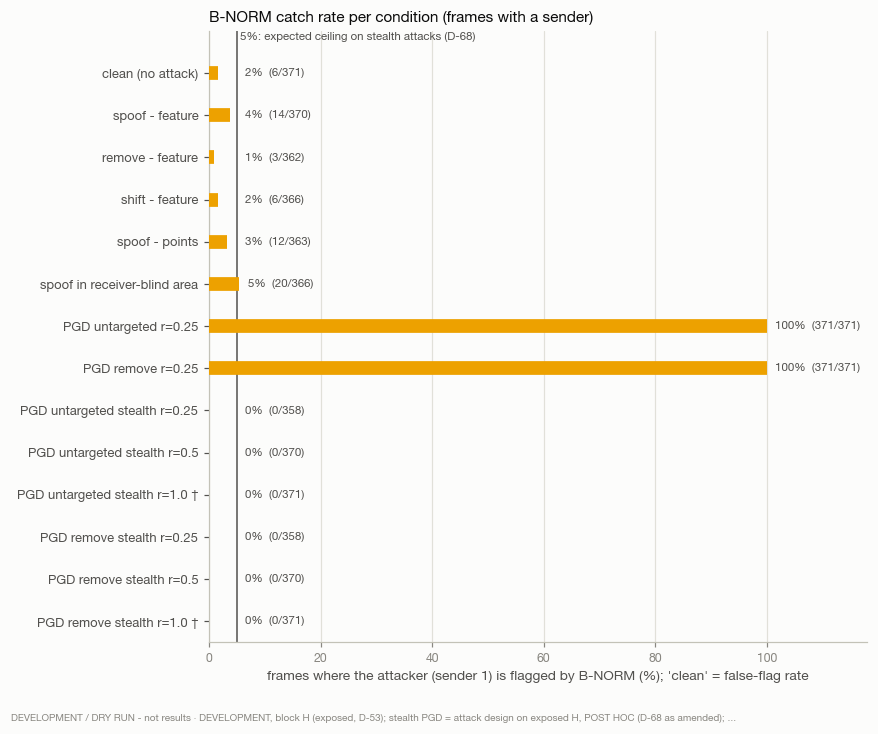

14 plotted values; first rows:
{'condition': 'clean', 'frames_n2': 371, 'applied': 371, 'sender1_flagged': 6, 'any_flagged': 6, 'catch_rate': 0.0162}
{'condition': 'spoof_feat', 'frames_n2': 371, 'applied': 370, 'sender1_flagged': 14, 'any_flagged': 14, 'catch_rate': 0.0378}
{'condition': 'remove_feat', 'frames_n2': 371, 'applied': 362, 'sender1_flagged': 3, 'any_flagged': 3, 'catch_rate': 0.0083}
{'condition': 'shift_feat', 'frames_n2': 371, 'applied': 366, 'sender1_flagged': 6, 'any_flagged': 6, 'catch_rate': 0.0164}


[None, None, None, None]

In [14]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['06_bnorm_catch']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 7. Attack strength

Attack loss per condition over all frames (with CI) and over the frames where the attack was realized.

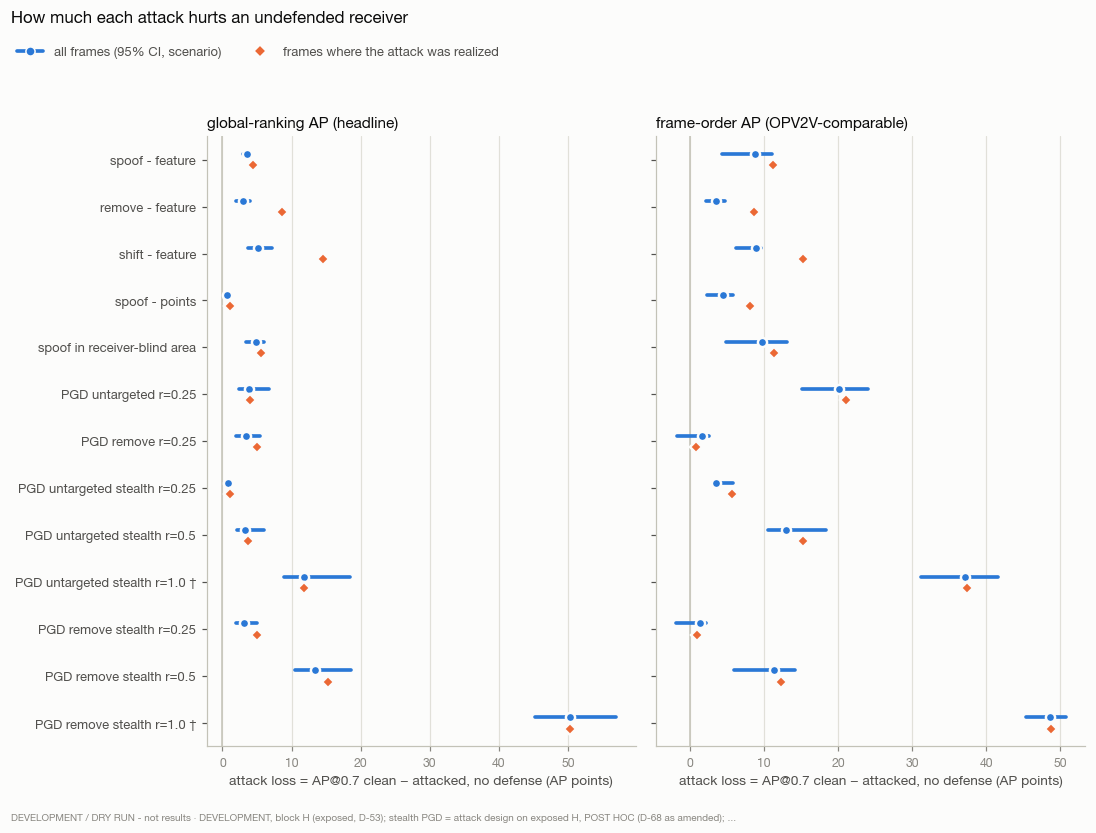

26 plotted values; first rows:
{'ap_definition': 'global', 'condition': 'spoof_feat', 'point': 0.03509, 'ci95_scenario_lo': 0.0299, 'ci95_scenario_hi': 0.0366, 'ci95_block10_lo': 0.029, 'ci95_block10_hi': 0.0411, 'realized_only_attack_loss': 0.0438, 'realized_frames': 248}
{'ap_definition': 'global', 'condition': 'remove_feat', 'point': 0.02942, 'ci95_scenario_lo': 0.0197, 'ci95_scenario_hi': 0.0397, 'ci95_block10_lo': 0.0224, 'ci95_block10_hi': 0.0369, 'realized_only_attack_loss': 0.0861, 'realized_frames': 38}
{'ap_definition': 'global', 'condition': 'shift_feat', 'point': 0.05116, 'ci95_scenario_lo': 0.0363, 'ci95_scenario_hi': 0.0718, 'ci95_block10_lo': 0.0376, 'ci95_block10_hi': 0.0668, 'realized_only_attack_loss': 0.146, 'realized_frames': 46}
{'ap_definition': 'global', 'condition': 'spoof_pts', 'point': 0.00651, 'ci95_scenario_lo': 0.0055, 'ci95_scenario_hi': 0.0078, 'ci95_block10_lo': 0.0047, 'ci95_block10_hi': 0.0084, 'realized_only_attack_loss': 0.011, 'realized_frames': 187

[None, None, None, None]

In [15]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['07_attack_strength']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 8. B-RAY removals

Boxes B-RAY removed, split by whether they matched a real car.

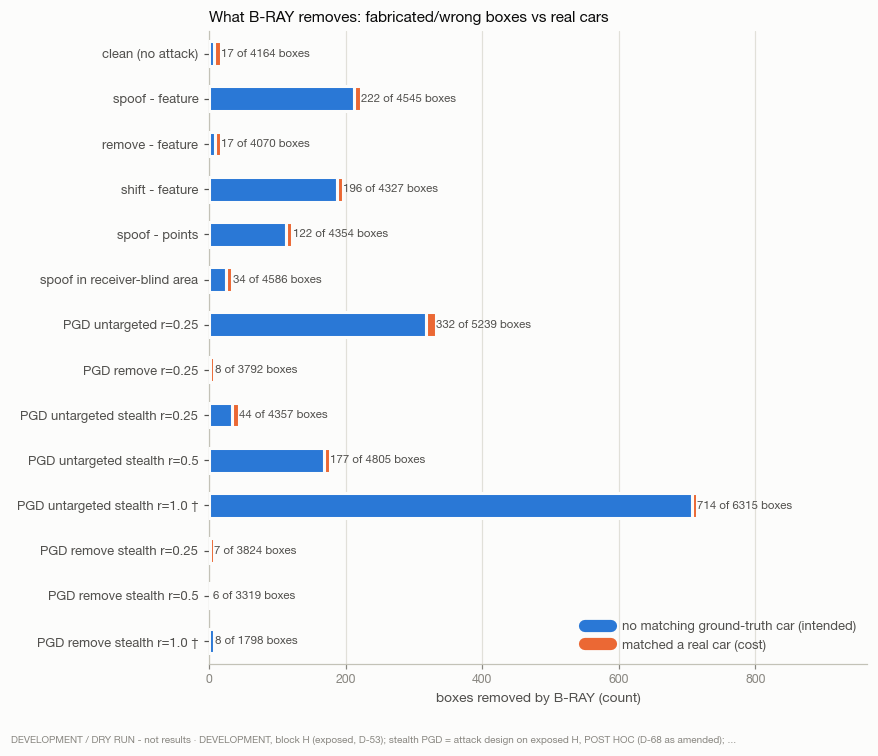

14 plotted values; first rows:
{'condition': 'clean', 'boxes': 4164, 'drop': 17, 'keep': 3514, 'keep_unknown': 273, 'keep_self': 360, 'frac_KNOWN': 0.848, 'dropped_gt_matched': 9, 'dropped_unmatched': 8}
{'condition': 'spoof_feat', 'boxes': 4545, 'drop': 222, 'keep': 3538, 'keep_unknown': 425, 'keep_self': 360, 'frac_KNOWN': 0.827, 'dropped_gt_matched': 9, 'dropped_unmatched': 213}
{'condition': 'remove_feat', 'boxes': 4070, 'drop': 17, 'keep': 3492, 'keep_unknown': 238, 'keep_self': 323, 'frac_KNOWN': 0.862, 'dropped_gt_matched': 8, 'dropped_unmatched': 9}
{'condition': 'shift_feat', 'boxes': 4327, 'drop': 196, 'keep': 3518, 'keep_unknown': 276, 'keep_self': 337, 'frac_KNOWN': 0.858, 'dropped_gt_matched': 9, 'dropped_unmatched': 187}


[None, None, None, None]

In [16]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['08_bray_boxes']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 9. R1 gating against ground truth

Contributions (sender × 6.4 m tile) R1 switched off, by their ground-truth label.

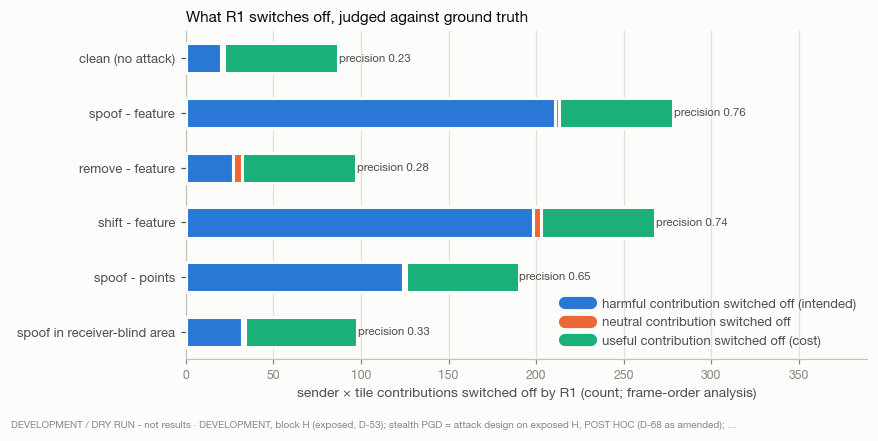

6 plotted values; first rows:
{'condition': 'clean', 'units': 1161, 'n_KNOWN': 518, 'frac_KNOWN': 0.446, 'gated': 87, 'gated_harmful': 20, 'gated_neutral': 2, 'false_rejections_useful': 65, 'precision': 0.23, 'harmful_units': 138, 'harmful_KNOWN': 93, 'useful_units': 862}
{'condition': 'spoof_feat', 'units': 1513, 'n_KNOWN': 732, 'frac_KNOWN': 0.484, 'gated': 278, 'gated_harmful': 211, 'gated_neutral': 2, 'false_rejections_useful': 65, 'precision': 0.759, 'harmful_units': 490, 'harmful_KNOWN': 307, 'useful_units': 863}
{'condition': 'remove_feat', 'units': 1105, 'n_KNOWN': 513, 'frac_KNOWN': 0.464, 'gated': 97, 'gated_harmful': 27, 'gated_neutral': 5, 'false_rejections_useful': 65, 'precision': 0.278, 'harmful_units': 159, 'harmful_KNOWN': 105, 'useful_units': 794}
{'condition': 'shift_feat', 'units': 1339, 'n_KNOWN': 706, 'frac_KNOWN': 0.527, 'gated': 268, 'gated_harmful': 198, 'gated_neutral': 5, 'false_rejections_useful': 65, 'precision': 0.739, 'harmful_units': 385, 'harmful_KNOWN'

[None, None, None, None]

In [17]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['09_r1_units']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

### Figure 10. Effect by number of cars

Mean ΔAP@0.7 over the 4 original attacks per agent count (frozen v2 analysis, frame-order AP).

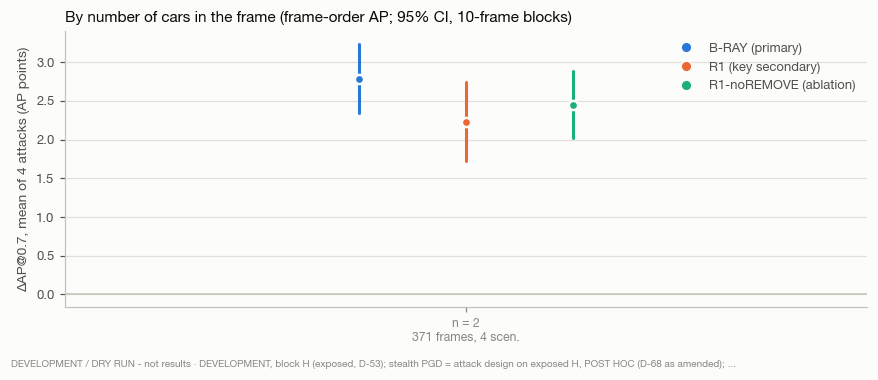

3 plotted values; first rows:
{'n_agents': 2, 'frames': 371, 'scenarios': 4, 'method': 'B-RAY', 'point': 0.02789, 'ci95_block10_lo': 0.0234, 'ci95_block10_hi': 0.0324}
{'n_agents': 2, 'frames': 371, 'scenarios': 4, 'method': 'R1', 'point': 0.02233, 'ci95_block10_lo': 0.0172, 'ci95_block10_hi': 0.0274}
{'n_agents': 2, 'frames': 371, 'scenarios': 4, 'method': 'R1_noREMOVE', 'point': 0.02443, 'ci95_block10_lo': 0.0202, 'ci95_block10_hi': 0.0289}


[None, None, None]

In [18]:
t = style.apply('light')
fn = dict((n, f) for n, _, f, _, _ in FIGURES)['10_by_agents']
fig, rows = fn(inp, t)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=110, bbox_inches='tight'); plt.close(fig)
display(Image(buf.getvalue()))
print(f'{len(rows)} plotted values; first rows:'); [print(r) for r in rows[:4]]

## Per-condition tables

In [19]:
for d in DEFS:
    display(Markdown(f'**{DEF_NAME[d]}**'))
    display(Markdown(T.per_family(inp, d)))

**global-ranking AP (headline)**

| Condition | B-RAY (primary) | R1 (key secondary) | R1-noREMOVE (ablation) | B-NORM (baseline) | Ego-only |
|---|---|---|---|---|---|
| clean (no attack) | -0.16 [-0.42, -0.02] | +0.10 [-0.23, +0.45] | -0.09 [-0.27, +0.00] | -0.31 [-0.45, -0.10] | -18.29 [-21.41, -15.64] |
| spoof - feature | +1.50 [+0.58, +2.01] | +1.65 [+0.92, +1.86] | +1.46 [+0.72, +1.88] | -0.74 [-1.00, -0.21] | -14.78 [-18.42, -11.94] |
| remove - feature | -0.14 [-0.34, -0.02] | +0.25 [-0.23, +0.59] | -0.03 [-0.23, +0.09] | -0.15 [-0.31, +0.00] | -15.35 [-19.09, -13.19] |
| shift - feature | +0.68 [+0.41, +0.94] | +1.10 [+1.02, +1.24] | +0.90 [+0.60, +1.27] | -0.23 [-0.43, +0.00] | -13.17 [-17.22, -10.06] |
| spoof - points | +0.21 [-0.02, +0.40] | +0.42 [+0.22, +0.58] | +0.24 [+0.07, +0.38] | -0.56 [-0.96, +0.00] | -17.64 [-20.66, -15.01] |
| spoof in receiver-blind area | +0.12 [-0.38, +0.41] | +0.31 [-0.06, +0.51] | +0.13 [-0.20, +0.31] | -0.80 [-1.21, -0.16] | -13.49 [-16.43, -11.43] |
| PGD untargeted r=0.25 | +0.14 [+0.03, +0.24] | +0.68 [+0.29, +1.23] | +0.38 [+0.14, +0.99] | -14.38 [-15.43, -12.25] | -14.38 [-15.43, -12.25] |
| PGD remove r=0.25 | -0.14 [-0.38, +0.00] | +1.11 [+0.35, +1.46] | -0.02 [-0.09, +0.00] | -14.93 [-16.15, -13.44] | -14.93 [-16.15, -13.44] |
| PGD untargeted stealth r=0.25 | -0.13 [-0.41, +0.01] | +0.02 [-0.45, +0.54] | -0.22 [-0.43, -0.03] | -0.21 [-0.44, +0.00] | -17.48 [-20.45, -15.14] |
| PGD untargeted stealth r=0.5 | -0.03 [-0.29, +0.10] | +0.40 [+0.04, +0.72] | -0.03 [-0.26, +0.22] | -0.18 [-0.44, +0.00] | -14.97 [-15.70, -13.05] |
| PGD untargeted stealth r=1.0 † | +0.40 [+0.24, +0.53] | +1.46 [+1.25, +1.98] | +1.16 [+0.77, +1.87] | +0.00 [+0.00, +0.00] | -6.51 [-8.90, -0.65] |
| PGD remove stealth r=0.25 | -0.12 [-0.35, +0.00] | +0.99 [+0.18, +1.33] | -0.08 [-0.21, -0.00] | -0.22 [-0.45, +0.00] | -15.16 [-16.48, -13.48] |
| PGD remove stealth r=0.5 | -0.10 [-0.14, -0.04] | +5.88 [+4.48, +7.06] | -0.06 [-0.15, +0.00] | -0.20 [-0.47, +0.00] | -4.83 [-5.97, -2.49] |
| PGD remove stealth r=1.0 † | -0.01 [-0.04, +0.02] | +27.29 [+23.07, +33.13] | +0.18 [+0.08, +0.33] | +0.00 [+0.00, +0.00] | +31.99 [+27.49, +37.91] |

**frame-order AP (OPV2V-comparable)**

| Condition | B-RAY (primary) | R1 (key secondary) | R1-noREMOVE (ablation) | B-NORM (baseline) | Ego-only |
|---|---|---|---|---|---|
| clean (no attack) | -0.08 [-0.32, +0.16] | -0.26 [-1.60, +0.44] | -0.02 [-0.23, +0.11] | -0.37 [-0.57, -0.11] | -20.97 [-23.35, -19.95] |
| spoof - feature | +4.90 [+1.38, +6.94] | +3.97 [-0.12, +5.60] | +4.17 [+1.18, +5.86] | -0.74 [-1.02, -0.32] | -12.19 [-19.09, -9.21] |
| remove - feature | -0.05 [-0.28, +0.18] | -0.10 [-1.54, +0.56] | +0.11 [-0.16, +0.23] | -0.19 [-0.44, +0.00] | -17.53 [-21.13, -15.95] |
| shift - feature | +3.93 [+0.69, +5.76] | +3.23 [+0.85, +4.52] | +3.43 [+0.68, +5.01] | -0.21 [-0.55, +0.00] | -12.06 [-17.19, -10.80] |
| spoof - points | +2.38 [+0.53, +3.42] | +1.83 [-0.81, +2.54] | +2.07 [+0.46, +2.89] | -0.63 [-1.02, +0.00] | -16.53 [-21.15, -14.48] |
| spoof in receiver-blind area | +0.33 [-0.10, +0.70] | +0.09 [-1.11, +0.50] | +0.26 [-0.04, +0.48] | -0.73 [-1.09, -0.24] | -11.22 [-17.63, -7.33] |
| PGD untargeted r=0.25 | +5.25 [+3.36, +6.86] | +4.77 [+3.23, +5.71] | +4.58 [+2.93, +5.69] | -0.79 [-5.40, +2.75] | -0.79 [-5.40, +2.75] |
| PGD remove r=0.25 | -0.10 [-0.33, +0.04] | +0.42 [-3.77, +1.21] | +0.01 [-0.08, +0.15] | -19.41 [-25.13, -18.90] | -19.41 [-25.13, -18.90] |
| PGD untargeted stealth r=0.25 | +0.70 [-0.00, +1.07] | +0.15 [-0.93, +0.86] | +0.23 [+0.10, +0.37] | -0.23 [-0.56, +0.00] | -17.48 [-18.87, -16.64] |
| PGD untargeted stealth r=0.5 | +3.02 [+1.53, +3.88] | +2.60 [+1.28, +2.88] | +2.37 [+1.80, +2.68] | -0.19 [-0.51, +0.00] | -8.09 [-10.06, -5.01] |
| PGD untargeted stealth r=1.0 † | +6.61 [+4.23, +8.44] | +6.58 [+4.57, +8.06] | +6.33 [+4.34, +8.11] | +0.00 [+0.00, +0.00] | +16.22 [+10.69, +20.97] |
| PGD remove stealth r=0.25 | -0.10 [-0.33, +0.04] | +0.31 [-3.61, +1.04] | -0.06 [-0.16, +0.00] | -0.24 [-0.58, +0.00] | -19.62 [-25.33, -18.93] |
| PGD remove stealth r=0.5 | -0.08 [-0.12, +0.03] | +5.35 [+0.77, +6.74] | -0.05 [-0.16, +0.02] | -0.21 [-0.57, +0.00] | -9.69 [-14.47, -7.90] |
| PGD remove stealth r=1.0 † | +0.12 [+0.06, +0.16] | +27.28 [+23.49, +30.49] | +0.33 [+0.20, +0.43] | +0.00 [+0.00, +0.00] | +27.73 [+24.71, +28.74] |

## PGD, B-NORM and descriptive expected-outcome checks

In [20]:
if inp.pgd_conditions:
    display(Markdown(T.pgd(inp)))
    e = T.expected_outcome_checks(inp)
    display(Markdown(e or 'no operational checks in the preregistration'))
    n = T.d70_note(inp)
    display(Markdown(n)) if n else None

| Condition | attack loss global | attack loss frame | recovery B-RAY (primary) (global / frame) | recovery R1 (key secondary) (global / frame) | recovery R1-noREMOVE (ablation) (global / frame) | recovery B-NORM (baseline) (global / frame) | recovery Ego-only (global / frame) | B-NORM catch | stealth-infeasible / frames with sender | realized / applied |
|---|---|---|---|---|---|---|---|---|---|---|
| PGD untargeted r=0.25 | +3.91 | +20.18 | 0.04 / 0.26 | 0.17 / 0.24 | 0.10 / 0.23 | -3.68 / -0.04 | -3.68 / -0.04 | 100% | 0/371 | 328/371 |
| PGD remove r=0.25 | +3.35 | +1.56 | -0.04 / -0.07 | 0.33 / 0.27 | -0.01 / 0.01 | -4.45 / -12.46 | -4.45 / -12.46 | 100% | 0/371 | 193/371 |
| PGD untargeted stealth r=0.25 | +0.81 | +3.49 | -0.16 / 0.20 | 0.03 / 0.04 | -0.27 / 0.07 | -0.26 / -0.07 | -21.51 / -5.01 | 0% | 13/371 | 192/358 |
| PGD untargeted stealth r=0.5 | +3.32 | +12.88 | -0.01 / 0.23 | 0.12 / 0.20 | -0.01 / 0.18 | -0.05 / -0.01 | -4.51 / -0.63 | 0% | 1/371 | 285/370 |
| PGD untargeted stealth r=1.0 † | +11.78 | +37.19 | 0.03 / 0.18 | 0.12 / 0.18 | 0.10 / 0.17 | 0.00 / 0.00 | -0.55 / 0.44 | 0% | 0/371 | 358/371 |
| PGD remove stealth r=0.25 | +3.13 | +1.35 | -0.04 / -0.07 | 0.32 / 0.23 | -0.03 / -0.05 | -0.07 / -0.18 | -4.84 / -14.55 | 0% | 13/371 | 181/358 |
| PGD remove stealth r=0.5 | +13.45 | +11.28 | -0.01 / -0.01 | 0.44 / 0.47 | -0.00 / -0.00 | -0.01 / -0.02 | -0.36 / -0.86 | 0% | 1/371 | 298/370 |
| PGD remove stealth r=1.0 † | +50.27 | +48.70 | -0.00 / 0.00 | 0.54 / 0.56 | 0.00 / 0.01 | 0.00 / 0.00 | 0.64 / 0.57 | 0% | 0/371 | 370/371 |

| Condition | B-RAY ≈ 0 (point recovery < 0.10 under both AP definitions) | R1 > 0 (R1 dAP@0.7 scenario-CI low > 0 under both AP definitions) | B-NORM ≤ 5% (sender-1 flag rate over attacked frames <= 0.05) |
|---|---|---|---|
| PGD untargeted r=0.25 | no | not applicable | not applicable |
| PGD remove r=0.25 | yes | no | not applicable |
| PGD untargeted stealth r=0.25 | no | not applicable | yes |
| PGD untargeted stealth r=0.5 | no | not applicable | yes |
| PGD untargeted stealth r=1.0 † | no | not applicable | yes |
| PGD remove stealth r=0.25 | yes | no | yes |
| PGD remove stealth r=0.5 | yes | yes | yes |
| PGD remove stealth r=1.0 † | yes | yes | yes |

† pgd_remove_stealth@r1.0, pgd_untargeted_stealth@r1.0: strong-attack level, added after seeing block-H development results (D-70, secondary; never used for a criterion).

## Realized-only effects

In [21]:
for d in DEFS:
    display(Markdown(f'**{DEF_NAME[d]}**'))
    display(Markdown(T.realized_only(inp, d)))

**global-ranking AP (headline)**

| Condition | realized frames | attack loss | B-RAY (primary) ΔAP (recovery) | R1 (key secondary) ΔAP (recovery) | R1-noREMOVE (ablation) ΔAP (recovery) | B-NORM (baseline) ΔAP (recovery) | Ego-only ΔAP (recovery) |
|---|---|---|---|---|---|---|---|
| spoof - feature | 248 | +4.38 | +1.87 (0.43) | +2.01 (0.46) | +1.76 (0.40) | -0.90 (-0.21) | -13.57 (-3.10) |
| remove - feature | 38 | +8.61 | -0.31 (-0.04) | +0.65 (0.07) | -0.31 (-0.04) | -0.87 (-0.10) | -15.44 (-1.79) |
| shift - feature | 46 | +14.60 | +0.28 (0.02) | +1.20 (0.08) | +1.04 (0.07) | +0.00 (0.00) | -10.42 (-0.71) |
| spoof - points | 187 | +1.10 | +0.59 (0.53) | +0.71 (0.65) | +0.52 (0.48) | -0.62 (-0.57) | -16.06 (-14.61) |
| spoof in receiver-blind area | 308 | +5.56 | +0.13 (0.02) | +0.24 (0.04) | +0.14 (0.03) | -0.98 (-0.18) | -12.81 (-2.30) |
| PGD untargeted r=0.25 | 328 | +3.97 | +0.16 (0.04) | +0.68 (0.17) | +0.35 (0.09) | -14.30 (-3.60) | -14.30 (-3.60) |
| PGD remove r=0.25 | 193 | +5.04 | -0.19 (-0.04) | +1.64 (0.33) | -0.04 (-0.01) | -14.59 (-2.90) | -14.59 (-2.90) |
| PGD untargeted stealth r=0.25 | 192 | +1.03 | -0.13 (-0.12) | +0.12 (0.12) | -0.27 (-0.26) | +0.00 (0.00) | -17.32 (-16.81) |
| PGD untargeted stealth r=0.5 | 285 | +3.70 | -0.03 (-0.01) | +0.43 (0.12) | -0.06 (-0.02) | +0.00 (0.00) | -14.61 (-3.95) |
| PGD untargeted stealth r=1.0 † | 358 | +11.75 | +0.40 (0.03) | +1.46 (0.12) | +1.15 (0.10) | +0.00 (0.00) | -6.36 (-0.54) |
| PGD remove stealth r=0.25 | 181 | +5.04 | -0.20 (-0.04) | +1.64 (0.33) | -0.08 (-0.02) | +0.00 (0.00) | -14.07 (-2.79) |
| PGD remove stealth r=0.5 | 298 | +15.22 | -0.11 (-0.01) | +6.62 (0.43) | -0.07 (-0.00) | +0.00 (0.00) | -3.50 (-0.23) |
| PGD remove stealth r=1.0 † | 370 | +50.34 | -0.01 (-0.00) | +27.33 (0.54) | +0.18 (0.00) | +0.00 (0.00) | +32.03 (0.64) |

**frame-order AP (OPV2V-comparable)**

| Condition | realized frames | attack loss | B-RAY (primary) ΔAP (recovery) | R1 (key secondary) ΔAP (recovery) | R1-noREMOVE (ablation) ΔAP (recovery) | B-NORM (baseline) ΔAP (recovery) | Ego-only ΔAP (recovery) |
|---|---|---|---|---|---|---|---|
| spoof - feature | 248 | +11.17 | +6.03 (0.54) | +4.97 (0.44) | +4.99 (0.45) | -0.91 (-0.08) | -9.40 (-0.84) |
| remove - feature | 38 | +8.59 | -0.21 (-0.02) | +0.14 (0.02) | -0.24 (-0.03) | -1.13 (-0.13) | -17.38 (-2.02) |
| shift - feature | 46 | +15.26 | +1.06 (0.07) | +1.24 (0.08) | +1.41 (0.09) | +0.00 (0.00) | -11.44 (-0.75) |
| spoof - points | 187 | +8.09 | +4.38 (0.54) | +3.60 (0.45) | +3.69 (0.46) | -0.57 (-0.07) | -11.62 (-1.44) |
| spoof in receiver-blind area | 308 | +11.32 | +0.34 (0.03) | +0.10 (0.01) | +0.27 (0.02) | -0.90 (-0.08) | -9.79 (-0.86) |
| PGD untargeted r=0.25 | 328 | +21.12 | +5.09 (0.24) | +4.52 (0.21) | +4.33 (0.20) | -0.16 (-0.01) | -0.16 (-0.01) |
| PGD remove r=0.25 | 193 | +0.83 | -0.14 (-0.17) | +0.16 (0.19) | +0.01 (0.01) | -21.01 (-25.32) | -21.01 (-25.32) |
| PGD untargeted stealth r=0.25 | 192 | +5.63 | +1.04 (0.18) | +0.31 (0.05) | +0.38 (0.07) | +0.00 (0.00) | -15.99 (-2.84) |
| PGD untargeted stealth r=0.5 | 285 | +15.27 | +3.42 (0.22) | +3.03 (0.20) | +2.75 (0.18) | +0.00 (0.00) | -6.43 (-0.42) |
| PGD untargeted stealth r=1.0 † | 358 | +37.50 | +6.59 (0.18) | +6.52 (0.17) | +6.28 (0.17) | +0.00 (0.00) | +16.63 (0.44) |
| PGD remove stealth r=0.25 | 181 | +0.88 | -0.20 (-0.23) | +0.11 (0.12) | -0.08 (-0.09) | +0.00 (0.00) | -20.69 (-23.46) |
| PGD remove stealth r=0.5 | 298 | +12.34 | -0.09 (-0.01) | +5.81 (0.47) | -0.05 (-0.00) | +0.00 (0.00) | -9.26 (-0.75) |
| PGD remove stealth r=1.0 † | 370 | +48.77 | +0.13 (0.00) | +27.32 (0.56) | +0.33 (0.01) | +0.00 (0.00) | +27.76 (0.57) |

## Interpretation (AUTHOR)

*To be written after reading the cells above. Keep to what the numbers support; quote the pre-registered statements as emitted.*

## Run provenance

In [22]:
import matplotlib, numpy, jinja2
print('python', platform.python_version(), '| numpy', numpy.__version__, '| matplotlib', matplotlib.__version__,
      '| jinja2', jinja2.__version__)
print('platform', platform.platform())
print('wall time %.1f s' % (time.time() - T0))

python 3.10.20 | numpy 1.26.4 | matplotlib 3.8.4 | jinja2 3.1.6
platform macOS-27.0-arm64-arm-64bit
wall time 2.9 s
